# `fig:calibration` for the paper

The calibration figure of the paper. The numbers are those of `three_channels_analysis/canal_1/canal1_classic_aleatoric_calibration.ipynb`, which this notebook only lays out.
Nothing upstream changes: same `pr_classic3` runs, same cross-model gene ranking, same donor Student-$t$ intervals, same precomputed no-H&E marginal baselines.

**Output: `results/_analysis/figures_paper/fig_calibration_paper_{RUN_ID}.pdf`**. Every notebook of `notebooks/paper_figures/` writes to this tree.

`pit_bias` is still computed and printed below (it costs nothing and the paper text may cite it); it is simply not drawn.

In [7]:
import sys
import importlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.append(str(PROJ))   # parent dir of src (notebooks are not pip-installed on the cluster)

import src.evaluation.benchmark_summary as bs
importlib.reload(bs)
from src.evaluation.benchmark_summary import (
    discover_run_summaries, gene_donor_matrix, donor_lopo_stats,
)

RUN_ID    = "pr_classic3"
RESULTS   = PROJ / "results"
DATASETS  = ["10x_TuPro", "TLS", "LUNG_CANCER"]
RADIUS    = "r75"
NS        = [50, 100, 500, 1000, 2000, None]   # None -> the full shared panel
CALIB     = ("ece_pit", "pit_bias", "disp_signed")   # all three computed; only 2 are drawn

# RANK_MODELS -- the SAME model set as canal1_classic_aleatoric.ipynb, and that matters: the gene
# ordering is the CROSS-MODEL donor-averaged Pearson, so ranking over a different set would
# silently give this figure a different x-axis from fig:mean-performance. msemeanonly is kept
# here for the ranking even though it has no predictive distribution (hence no PIT columns).
RANK_MODELS = ["msemeanonly", "homoscedastic", "heteroscedastic", "spot_homoscedastic",
               "poisson_cp", "negativebinomial_hetero_noanchor_cp",
            #    "negativebinomial_spotdisp_cp", "negativebinomial_genedisp_cp"
               ]

# FIG_MODELS -- what the figure DRAWS. One curve per family branch. The two restricted-dispersion
# NB heads are reported as numbers, not as curves.
FIG_MODELS = ["homoscedastic", "heteroscedastic", "spot_homoscedastic",
              "poisson_cp", "negativebinomial_hetero_noanchor_cp"]

summaries = discover_run_summaries(RESULTS, RUN_ID, DATASETS, radius=RADIUS,
                                   models=RANK_MODELS, lambda_keep=0.0)
print(f"{len(summaries)} runs cp/gaussian")
for s in summaries:
    has = "PIT" if "ece_pit" in s["per_long"].columns else "no PIT"
    print(f"   {s['dataset']:<12s} {s['label']:<42s} {has}")

_found = {s["label"].split("|")[0] for s in summaries}
_missing = [m for m in RANK_MODELS if m not in _found]
if _missing:
    print(f"\n(!) models requested but not found: {_missing}")

18 runs cp/gaussian
   10x_TuPro    heteroscedastic|lam0.0                     PIT
   10x_TuPro    homoscedastic|lam0.0                       PIT
   10x_TuPro    msemeanonly                                no PIT
   10x_TuPro    negativebinomial_hetero_noanchor_cp        PIT
   10x_TuPro    poisson_cp                                 PIT
   10x_TuPro    spot_homoscedastic|lam0.0                  PIT
   TLS          heteroscedastic|lam0.0                     PIT
   TLS          homoscedastic|lam0.0                       PIT
   TLS          msemeanonly                                no PIT
   TLS          negativebinomial_hetero_noanchor_cp        PIT
   TLS          poisson_cp                                 PIT
   TLS          spot_homoscedastic|lam0.0                  PIT
   LUNG_CANCER  heteroscedastic|lam0.0                     PIT
   LUNG_CANCER  homoscedastic|lam0.0                       PIT
   LUNG_CANCER  msemeanonly                                no PIT
   LUNG_CANCER  negativebi

## 1. Cumulative trajectories: model (H&E) vs marginal baseline (no H&E), on the same gene ranking

The ranking is the one of `fig:mean-performance` (Pearson averaged over donors, then over models, decreasing). The baselines carry no Pearson, so they do not take part in the ranking: they are simply laid on it, which is the whole point (same axis, same gene subset at every cutoff).

The baseline is model-independent by construction (same LOPO donors, same v5/r75 panel, same `depth_scale`). The cell checks that (donors + genes) instead of assuming it.

In [8]:
BASELINE_DIR = PROJ / "results" / "_analysis" / "canal1_marginal_baseline"
BASE_FAMILIES = ("gaussian", "poisson", "nb")


def shared_order(group):
    """Genes shared by every model of the group, ranked by the cross-model donor-averaged Pearson.

    Identical construction to cutoff_donor_points / Figure 4, written out here because the
    baselines carry no Pearson column and must be laid on that SAME ranking.
    """
    shared, pieces = None, []
    for s in group:
        mat = gene_donor_matrix(s["per_long"], "pearson")
        shared = set(mat.index) if shared is None else shared & set(mat.index)
        pieces.append(mat.mean(axis=1))
    shared = sorted(shared)
    return (pd.concat(pieces, axis=1).loc[shared].mean(axis=1)
            .sort_values(ascending=False).index)


def cumulative_donor_ci(mat, order, ns):
    """(gene x donor) matrix -> cumulative mean over the first n ranked genes + donor 95% CI.

    Genes are averaged WITHIN each donor first (K points), then donor_lopo_stats gives the
    Student-t interval on the mean. The resampling unit is the patient = the LOPO split unit.
    """
    mat = mat.reindex(order)
    rows = []
    for n in ns:
        st = donor_lopo_stats(mat.iloc[:n].mean(axis=0, skipna=True).to_dict())
        rows.append(dict(n=n, mean=st["mean"], sem=st["sem"], K=st["K"],
                         ci_lo=st["ci95_mean"][0], ci_hi=st["ci95_mean"][1]))
    return pd.DataFrame(rows).set_index("n")


# CURVES[ds] = {"ns", "order", "model": {(model_type, metric): curve}, "baseline": {(fam, metric): curve}}
CURVES = {}
for ds in DATASETS:
    group = [s for s in summaries if s["dataset"] == ds]
    if not group:
        continue
    order = shared_order(group)
    ns = sorted({(len(order) if n is None else min(n, len(order))) for n in NS})
    entry = {"ns": ns, "order": order, "model": {}, "baseline": {}}

    for s in group:
        if "ece_pit" not in s["per_long"].columns:
            continue                                  # msemeanonly: ranking only, no calibration
        for m in CALIB:
            entry["model"][(s["model_type"], m)] = cumulative_donor_ci(
                gene_donor_matrix(s["per_long"], m), order, ns)

    bl = pd.read_parquet(BASELINE_DIR / f"{ds}.parquet")   # family,test_donor,gene,<CALIB>
    bl_donors = set(bl["test_donor"].astype(str))
    md_donors = set(map(str, gene_donor_matrix(group[0]["per_long"], "pearson").columns))
    assert bl_donors == md_donors, f"{ds}: baseline donors {sorted(bl_donors)} != model {sorted(md_donors)}"
    n_common = len(set(bl["gene"]) & set(order))
    assert n_common >= 0.99 * len(order), f"{ds}: only {n_common}/{len(order)} genes in common"

    for fam in BASE_FAMILIES:
        sub = bl[bl["family"] == fam]
        if sub.empty:
            continue
        for m in CALIB:
            piv = sub.pivot_table(index="gene", columns="test_donor", values=m)
            entry["baseline"][(fam, m)] = cumulative_donor_ci(piv, order, ns)

    CURVES[ds] = entry
    print(f"{ds:<12s} {len(order):,} shared genes, cutoffs {ns}, "
          f"{len({k[0] for k in entry['model']})} models + {len({k[0] for k in entry['baseline']})} baselines")


# Printed twin of the figure: one table per (dataset, metric), rows = model then baseline.
for ds, entry in CURVES.items():
    print(f"\n\n=== {ds} — cumulative trajectories [mean (donor 95% CI on the mean)] ===")
    print(f"    n top genes = {entry['ns']}")
    for m in CALIB:
        rows = {}
        for mt in RANK_MODELS:
            cur = entry["model"].get((mt, m))
            if cur is not None:
                rows[mt] = {n: f"{r['mean']:.4f} ({r['ci_lo']:.4f}, {r['ci_hi']:.4f})"
                            for n, r in cur.iterrows()}
        for fam in BASE_FAMILIES:
            cur = entry["baseline"].get((fam, m))
            if cur is not None:
                rows[f"baseline:{fam} (no H&E)"] = {
                    n: f"{r['mean']:.4f} ({r['ci_lo']:.4f}, {r['ci_hi']:.4f})" for n, r in cur.iterrows()}
        drawn = " (DRAWN)" if m != "pit_bias" else " (computed, NOT drawn in the paper figure)"
        print(f"\n[{m}]{drawn}")
        print(pd.DataFrame(rows).T.reindex(columns=entry["ns"]).to_string())

10x_TuPro    3,000 shared genes, cutoffs [50, 100, 500, 1000, 2000, 3000], 5 models + 3 baselines
TLS          3,000 shared genes, cutoffs [50, 100, 500, 1000, 2000, 3000], 5 models + 3 baselines
LUNG_CANCER  3,000 shared genes, cutoffs [50, 100, 500, 1000, 2000, 3000], 5 models + 3 baselines


=== 10x_TuPro — cumulative trajectories [mean (donor 95% CI on the mean)] ===
    n top genes = [50, 100, 500, 1000, 2000, 3000]

[ece_pit] (DRAWN)
                                                        50                       100                      500                      1000                     2000                     3000
homoscedastic                        0.1775 (0.1467, 0.2084)  0.1743 (0.1489, 0.1996)  0.1715 (0.1526, 0.1905)  0.1722 (0.1552, 0.1892)  0.1713 (0.1575, 0.1851)  0.1840 (0.1730, 0.1950)
heteroscedastic                      0.2041 (0.1650, 0.2433)  0.1959 (0.1623, 0.2295)  0.1835 (0.1537, 0.2132)  0.1795 (0.1554, 0.2035)  0.1741 (0.1570, 0.1913)  0.1823 (0.1684, 0.1961

## 2. The paper figure — 2 PIT scalars x 3 cohorts, legend on the LEFT

Solid = model (H&E); **dashed = the no-H&E baseline of the same family**, in the color of that family's model (black for the Gaussian, which has three). The vertical gap between a solid line and its dashed counterpart IS what histology adds to calibration.



legend strip = 0.222 of the figure width -> 2.11 in per panel
written: fig_calibration_paper_pr_classic3.pdf


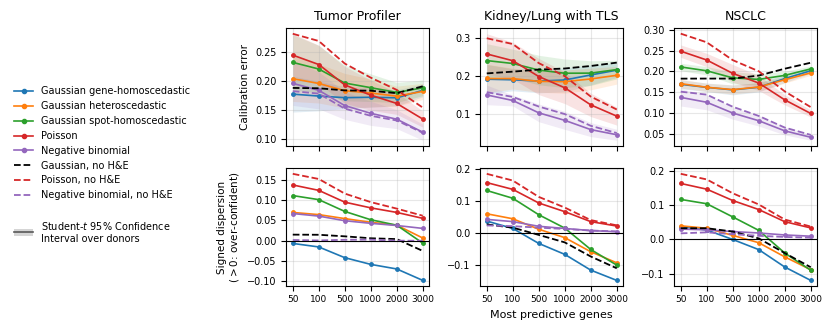

In [9]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.legend_handler import HandlerTuple

# Canonical model -> color map, keyed on model_type, IDENTICAL to canal1_classic_aleatoric.ipynb so a
# model keeps one color across every figure of the paper.
MODEL_COLORS = {
    "homoscedastic":                       "#1f77b4",   # blue
    "heteroscedastic":                     "#ff7f0e",   # orange
    "spot_homoscedastic":                  "#2ca02c",   # green
    "poisson_cp":                          "#d62728",   # red    -- Poisson family
    "negativebinomial_hetero_noanchor_cp": "#9467bd",   # purple -- NB family, free dispersion
}
MODEL_LABELS = {
    "homoscedastic":                       "Gaussian gene-homoscedastic",
    "heteroscedastic":                     "Gaussian heteroscedastic",
    "spot_homoscedastic":                  "Gaussian spot-homoscedastic",
    "poisson_cp":                          "Poisson",
    "negativebinomial_hetero_noanchor_cp": "Negative binomial",
}
# Baseline dashed in its family's model color -> the model/baseline pairing is immediate.
# The Gaussian family has three models and no single color, so its baseline is black.
BASELINE_COLORS = {"gaussian": "black", "poisson": "#d62728", "nb": "#9467bd"}
BASELINE_LABELS = {"gaussian": "Gaussian, no H&E", "poisson": "Poisson, no H&E",
                   "nb": "Negative binomial, no H&E"}
DATASET_LABELS = {"10x_TuPro": "Tumor Profiler", "TLS": "Kidney/Lung with TLS",
                  "LUNG_CANCER": "NSCLC"}

# Rows of the figure: (metric, y label, draw the donor CI band?). The location-bias row
# ("pit_bias") is deliberately absent -- vertical space is the cost in the paper.
METRIC_ROWS = [
    ("ece_pit",     "Calibration error", True),
    # ("disp_signed", "Signed dispersion\n($>0$: over-confident,\n$<0$: under-confident)", False),
    ("disp_signed", "Signed dispersion\n($>0$: over-confident)", False),

]

FIGSIZE       = (8.3, 3.4)   # wide + short: LaTeX scales to a fixed width, so width is the cheap axis
LEGEND_FS     = 7            # legend font size -- it is what sets the legend's width, see below
LEGEND_GUTTER = 0.015        # blank fraction of the width between the legend and the y labels

ds_plot = [ds for ds in DATASETS if ds in CURVES]
fig, axes = plt.subplots(len(METRIC_ROWS), len(ds_plot), figsize=FIGSIZE, sharex="col")

for j, ds in enumerate(ds_plot):
    entry = CURVES[ds]
    x = np.arange(len(entry["ns"]))
    for i, (metric, _ylab, band) in enumerate(METRIC_ROWS):
        ax = axes[i, j]
        for mt in FIG_MODELS:                              # fixed order -> stable colors/legend
            cur = entry["model"].get((mt, metric))
            if cur is None:
                continue
            c = MODEL_COLORS[mt]
            if band:
                ax.fill_between(x, cur["ci_lo"], cur["ci_hi"], color=c, alpha=0.13, linewidth=0)
            ax.plot(x, cur["mean"], "-o", ms=2.5, lw=1.2, color=c)
        for fam in BASE_FAMILIES:
            cur = entry["baseline"].get((fam, metric))
            if cur is None:
                continue
            ax.plot(x, cur["mean"], "--", lw=1.3, color=BASELINE_COLORS[fam])
        if metric != "ece_pit":
            ax.axhline(0, color="black", lw=0.8)
        ax.grid(alpha=0.3)
        ax.tick_params(labelsize=7)
    axes[0, j].set_title(DATASET_LABELS.get(ds, ds), fontsize=9)
    axes[-1, j].set_xticks(x)
    axes[-1, j].set_xticklabels([str(n) for n in entry["ns"]], fontsize=6.5)
    # ONE x label for the three columns, under the MIDDLE one: three copies of the same
    # text overlapped from column to column. All columns share a width, so the center of the
    # middle column IS the center of the grid.
    if j == len(ds_plot) // 2:
        axes[-1, j].set_xlabel("Most predictive genes", fontsize=8)

for i, (_metric, ylab, _band) in enumerate(METRIC_ROWS):
    axes[i, 0].set_ylabel(ylab, fontsize=7.5)

handles = ([Line2D([0], [0], color=MODEL_COLORS[mt], marker="o", ms=3, lw=1.2,
                   label=MODEL_LABELS[mt]) for mt in FIG_MODELS]
           + [Line2D([0], [0], color=BASELINE_COLORS[f], lw=1.3, ls="--",
                     label=BASELINE_LABELS[f]) for f in BASE_FAMILIES])

# The BAND needs a legend entry of its own. COMPOSITE entry: a line drawn on top of a
# patch, both in the SAME legend box -- HandlerTuple(ndivide=1) does not split the box, it
# overlays. GRAY and not black: black is already the dashed no-H&E Gaussian baseline, and two
# black entries in one legend read as related. The swatch alpha is raised above the plot's
BAND_GRAY = "0.35"
band_handle = (Patch(facecolor=BAND_GRAY, alpha=0.25, linewidth=0),
               Line2D([0], [0], color=BAND_GRAY, lw=1.2))
spacer = Line2D([], [], ls="", marker="", label="")
# A tuple handle carries no label of its own, so labels must be passed explicitly once one
# entry is a tuple. Two lines rather than one: the strip width is what the panels pay.
labels = [h.get_label() for h in handles] + ["", "Student-$t$ 95% Confidence \nInterval over donors"]
leg = fig.legend(handles=handles + [spacer, band_handle], labels=labels,
                 handler_map={tuple: HandlerTuple(ndivide=1)},
                 loc="center left", bbox_to_anchor=(0.0, 0.5),
                 ncol=1, frameon=False, fontsize=LEGEND_FS)
fig.canvas.draw()
legend_w = leg.get_window_extent().width / fig.bbox.width
plt.tight_layout(rect=[legend_w + LEGEND_GUTTER, 0, 1, 1])
print(f"legend strip = {legend_w:.3f} of the figure width "
      f"-> {FIGSIZE[0] * (1 - legend_w - LEGEND_GUTTER) / len(ds_plot):.2f} in per panel")

# The figure tree of the paper. The "_paper" suffix repeats the directory on purpose, so the
# file name alone still says which layout it is.
FIG_DIR = PROJ / "results" / "_analysis" / "figures_paper"
FIG_DIR.mkdir(parents=True, exist_ok=True)
for ext in ("pdf", "png"):
    fig.savefig(FIG_DIR / f"fig_calibration_paper_{RUN_ID}.{ext}", dpi=300, bbox_inches="tight")
print("written:", f"fig_calibration_paper_{RUN_ID}.pdf")
plt.show()